In [1]:
#import

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from copy import deepcopy
from scipy.linalg import solve_continuous_are


In [2]:
# Define our state
x, y, z, x_dot, y_dot, z_dot, theta, phi, gamma, p,q,r, n_1, n_2, n_3, n_4 = sp.symbols(r'x y z \dot{x} \dot{y} \dot{z} theta phi gamma p q r n_1 n_2 n_3 n_4')
state = sp.Matrix([x, y, z, x_dot, y_dot, z_dot, theta, phi, gamma, p,q,r])
state_sym = deepcopy(state)
units_vec = sp.Matrix(['meters', 'meters', 'meters', 'meters/second', 'meters/second', 'meters/second', 'radians', 'radians', 'radians','radians/second', 'radians/second', 'radians/second'])
u = sp.Matrix([n_1, n_2, n_3, n_4])
u_sym = deepcopy(u)


# Define constants

Ixx, Iyy, Izz = 0.0182, 0.0169, 0.0253
Inertia = sp.diag(Ixx, Iyy, Izz)

m = 1.4367
g = 9.81

l = 0.25
angle_arm = sp.pi/4

# Define the Rotation Matrix

def get_R_ItoB(theta, phi, gamma):
    R_ItoB = sp.Matrix([
        [sp.cos(gamma)*sp.cos(phi), sp.sin(gamma)*sp.cos(phi), -sp.sin(phi)],
        [sp.cos(gamma)*sp.sin(phi)*sp.sin(theta) - sp.sin(gamma)*sp.cos(theta), sp.sin(gamma)*sp.sin(phi)*sp.sin(theta) + sp.cos(gamma)*sp.cos(theta), sp.cos(phi)*sp.sin(theta)],
        [sp.cos(gamma)*sp.sin(phi)*sp.cos(theta) + sp.sin(gamma)*sp.sin(theta), sp.sin(gamma)*sp.sin(phi)*sp.cos(theta) - sp.cos(gamma)*sp.sin(theta), sp.cos(phi)*sp.cos(theta)]
    ])
    return R_ItoB

# u


In [3]:
# Define the RPM to thurst equation

# rpm = sp.Matrix([1,1,1,1]) #

density = 1.225
CT = 0.094
D = 0.254

def get_thrust(rpm_vec):
    thrust = sp.Matrix([0, 0, (CT * density * D**4 * rpm_vec.applyfunc(lambda x: (x/60)**2)).dot(sp.ones(4,1))])
    return thrust # thrust from rpm

def get_thrust_components(rpm_vec):
    return (CT * density * D**4 * rpm_vec.applyfunc(lambda x: (x/60)**2))

#get_thrust()
# sp.ones(4,1)


# Define the torque equations and lever arms
angles_arms = sp.Matrix([angle_arm,sp.pi - angle_arm, angle_arm + sp.pi, -angle_arm])
kq = 0.055

def get_torques(u):
    T_vec = get_thrust_components(u)
    tau = sp.zeros(3, 1)
    for T, angle in zip(T_vec, angles_arms):
        r = l*sp.Matrix([sp.cos(angle), sp.sin(angle), 0])
        tau += r.cross(sp.Matrix([0, 0, T]))
    tau += sp.Matrix([0, 0, kq * D * (T_vec[0] - T_vec[1] + T_vec[2] - T_vec[3])])
    return tau




In [4]:
# position ODE

def ODE_velocity(state, u):

    v_body = sp.Matrix(state[3:6])

    angular_v = sp.Matrix(state[9:12]) # angular body
    F_thrust = get_thrust(u)

    R_IB = get_R_ItoB(*state[6:9])
    F_g = R_IB * sp.Matrix([0,0,-m*g])
    F_body = F_thrust + F_g
    v_body_dot = F_body/m - angular_v.cross(v_body)
    return v_body_dot

def ODE_position(state):
    R_BI = get_R_ItoB(*state[6:9]).T # same as inverse = transpose for rotation matrix
    return R_BI * sp.Matrix(state[3:6])

# ODE_position(sp.zeros(12,1), sp.zeros(4,1))

In [5]:
# rotational ODE

def ODE_angular_vel(state,u):
    angular_vel = sp.Matrix(state[9:])
    tau = get_torques(u=u)
    angular_accel_body = Inertia.inv() * (tau - angular_vel.cross(Inertia*angular_vel) )
    return angular_accel_body

def ODE_euler_angle(state):
    theta, phi, gamma = state[6:9]
    R = sp.Matrix([
        [1, sp.sin(theta)*sp.tan(phi),  sp.cos(theta)*sp.tan(phi)],
        [0, sp.cos(theta),             -sp.sin(theta)],
        [0, sp.sin(theta)/sp.cos(phi),  sp.cos(theta)/sp.cos(phi)]
    ])
    return R * sp.Matrix([state[9:]]).T


In [6]:
# define function of f

def ODE(state,u):
    f = sp.Matrix([ODE_position(state), ODE_velocity(state,u), ODE_euler_angle(state), ODE_angular_vel(state,u)])
    return f
ODE(state=state,u = u)

Matrix([
[        \dot{x}*cos(gamma)*cos(phi) + \dot{y}*(-sin(gamma)*cos(theta) + sin(phi)*sin(theta)*cos(gamma)) + \dot{z}*(sin(gamma)*sin(theta) + sin(phi)*cos(gamma)*cos(theta))],
[         \dot{x}*sin(gamma)*cos(phi) + \dot{y}*(sin(gamma)*sin(phi)*sin(theta) + cos(gamma)*cos(theta)) + \dot{z}*(sin(gamma)*sin(phi)*cos(theta) - sin(theta)*cos(gamma))],
[                                                                                             -\dot{x}*sin(phi) + \dot{y}*sin(theta)*cos(phi) + \dot{z}*cos(phi)*cos(theta)],
[                                                                                                                                     \dot{y}*r - \dot{z}*q + 9.81*sin(phi)],
[                                                                                                                         -\dot{x}*r + \dot{z}*p - 9.81*sin(theta)*cos(phi)],
[      \dot{x}*q - \dot{y}*p + 9.26680909527234e-8*n_1**2 + 9.26680909527234e-8*n_2**2 + 9.26680909527234e-8*n_3**2 + 9.2

In [7]:
# Design LQR

rpm_hover = 60 * np.sqrt((m*g)/(4*CT*density*D**4))
u_eq = sp.Matrix([rpm_hover,rpm_hover,rpm_hover,rpm_hover])
state_eq = sp.zeros(12,1)
eq_subs = dict(zip(list(state_sym) + list(u_sym), list(state_eq) + list(u_eq)))


f = ODE(state,u)
A = sp.N(f.jacobian(state).subs(eq_subs))
B = sp.N(f.jacobian(u).subs(eq_subs))

# state space model Ax + B(-Kx) = y
state_max = [0.05,0.05,0.05,0.2,0.2,0.2,sp.rad(10), sp.rad(10),sp.rad(15),sp.rad(60),sp.rad(60), sp.rad(60)]
Q = sp.N(sp.diag(*[1 / value**2 for value in state_max]))
control_max = [4000.0, 4000.0, 4000.0, 4000.0]
R = sp.N(sp.diag(*[1 / value**2 for value in control_max]))

P = solve_continuous_are(np.array(A.tolist(), dtype=float),np.array(B.tolist(),dtype=float),np.array(Q.tolist(),dtype=float),np.array(R.tolist(),dtype=float))

K = R.inv() @ B.T @ sp.Matrix(P)


In [8]:
def get_to_target(x_0, target_state, time, dt):
    cost_integral = sp.Matrix([0])

    steps = time/dt
    state_hist = []
    u_history = []
    time_hist = []
    x = x_0
    for i in range(int(steps)):
        t = i * dt
        du = -K*(x-target_state)
        current_u = u_eq + du

        state_cost = x.T * Q * x
        control_cost = current_u.T * R * current_u
        cost_integral += (state_cost + control_cost) * dt


        state_hist.append(x)
        u_history.append(current_u)

        dx = A*x + B*du
        x = x + dx * dt
        time_hist.append(t)

    achieved = False
    if (target_state - state_hist[-1]).norm() < 0.1:
        achieved = True
    return time_hist, state_hist, achieved

def follow_path(path_list, time):
    cost_integral = sp.Matrix([0])
    dt = time[-1] - time[-2]
    # steps = time/dt
    state_hist = []
    u_history = []
    time_hist = []
    vector_trj = path_list[0]
    if len(vector_trj) == 12:
        target_state = sp.Matrix(vector_trj) # multi sizing
    else:
        target_state = sp.Matrix(list(vector_trj) + [0] * (12 - len(vector_trj)))
    x = target_state
    for t,vector_trj in zip(time, path_list):
        if len(vector_trj) == 12:
            target_state = sp.Matrix(vector_trj) # multi sizing
        else:
            target_state = sp.Matrix(list(vector_trj) + [0] * (12 - len(vector_trj)))
        du = -K*(x-target_state)
        current_u = u_eq + du

        state_cost = x.T * Q * x
        control_cost = current_u.T * R * current_u
        cost_integral += (state_cost + control_cost) * dt


        state_hist.append(x)
        u_history.append(current_u)

        dx = A*x + B*du
        x = x + dx * dt
        time_hist.append(t)

    return time_hist, state_hist


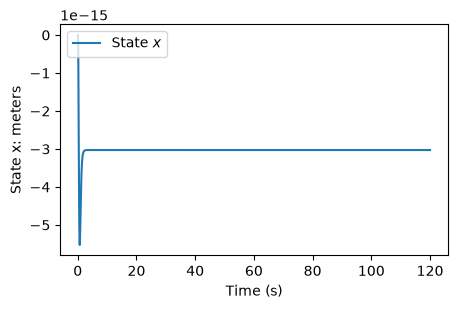

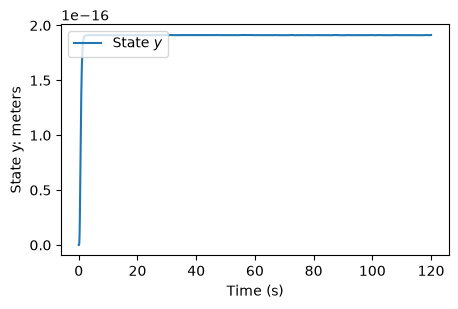

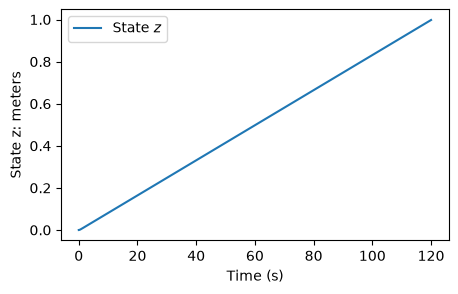

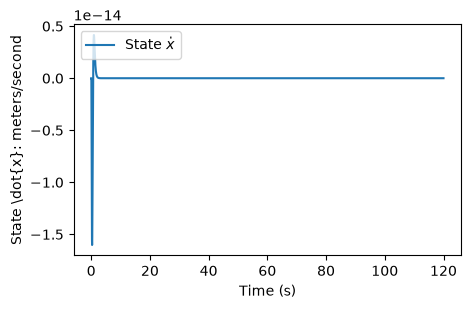

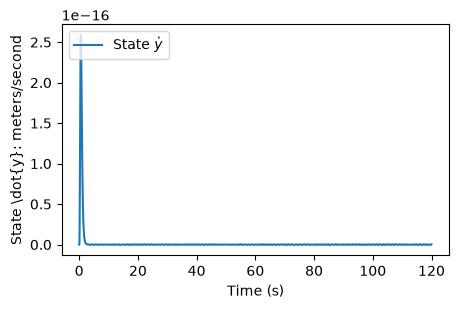

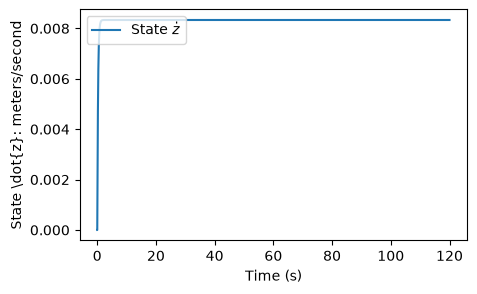

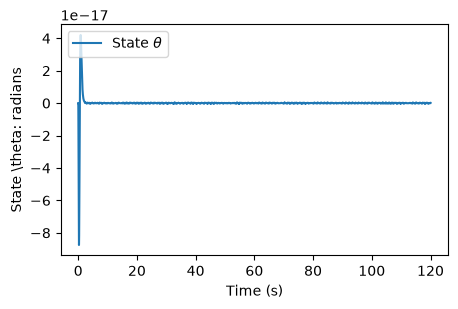

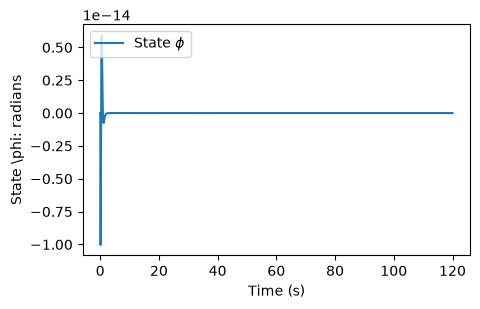

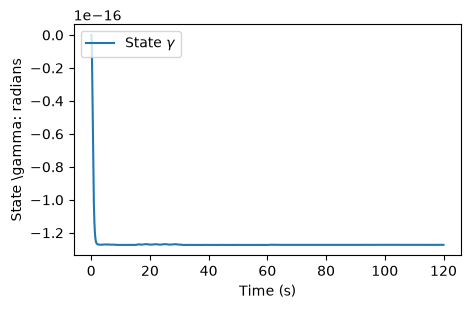

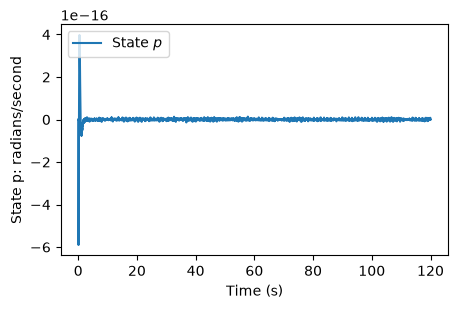

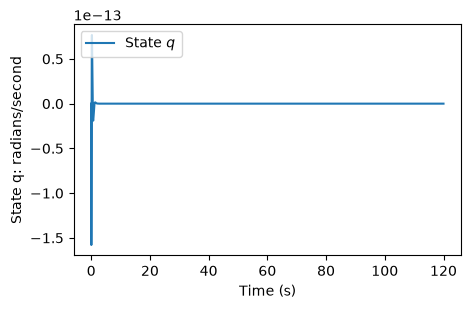

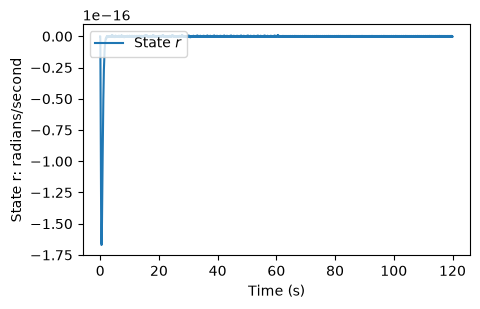

In [9]:
# Test 1: Hover 1 m above ground

target_state = np.array([0,0,1, 0, 0, 0, 0, 0, 0, 0, 0, 0])
initial_state = np.array([0,0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

def get_straight_path_z(initial_state, target_state, steps):
    z_linspace = np.linspace(initial_state[2], target_state[2], steps)
    state_hist = []
    time_hist = []
    current_time = 0.0
    dt = 0.01
    for z_var in z_linspace:
        state_hist.append(sp.Matrix([0,0,z_var, 0,0,0, 0,0,0,0,0,0]))
        current_time += dt
        time_hist.append(current_time)
    return state_hist, time_hist

states, times = get_straight_path_z(initial_state, target_state, 12000)
time_hist, state_hist = follow_path(states, times)


states_np = np.array([np.array(s.tolist(), dtype=float).flatten() for s in state_hist])

for value in range(states_np.shape[1]):
    plt.figure(figsize=(5, 3))
    plt.plot(time_hist, states_np[:, value], label=f"State {f"${sp.latex(state_sym[value])}$"}")
    plt.legend(loc="upper left")
    plt.xlabel("Time (s)")
    plt.ylabel(f"State {sp.latex(state_sym[value])}: {units_vec[value]}")


plt.show()


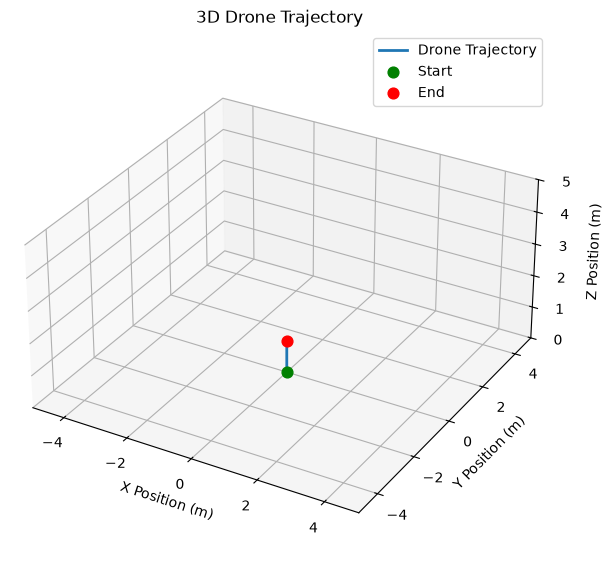

In [10]:
states_np = np.array([np.array(s.tolist(), dtype=float).flatten() for s in state_hist])

x = states_np[:, 0]
y = states_np[:, 1]
z = states_np[:, 2]

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')

ax.plot(x, y, z, label="Drone Trajectory", linewidth=2)

ax.scatter(x[0], y[0], z[0], color='green', s=60, label="Start")
ax.scatter(x[-1], y[-1], z[-1], color='red', s=60, label="End")

ax.set_xlabel("X Position (m)")
ax.set_ylabel("Y Position (m)")
ax.set_zlabel("Z Position (m)")
ax.set_xlim([-5,5])
ax.set_ylim([-5,5])
ax.set_zlim([0,5])
ax.set_title("3D Drone Trajectory")
ax.set_aspect('equal')
ax.legend()
plt.show()


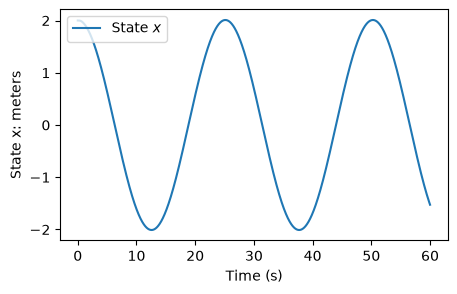

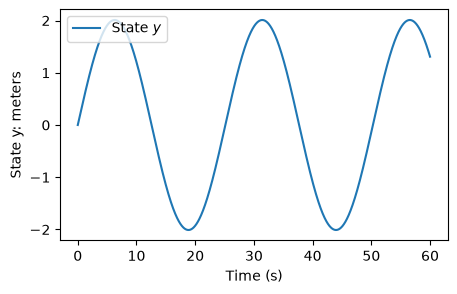

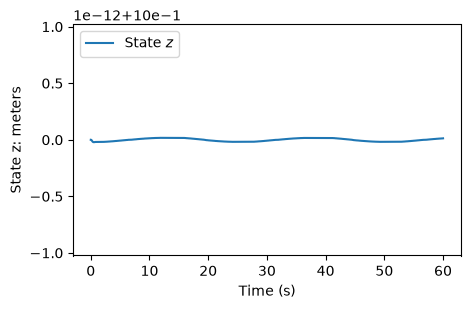

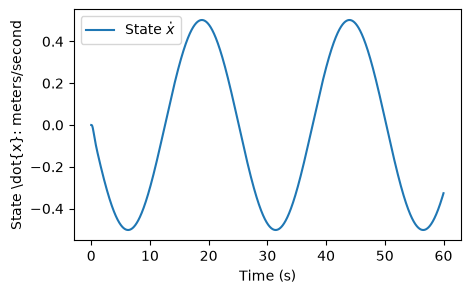

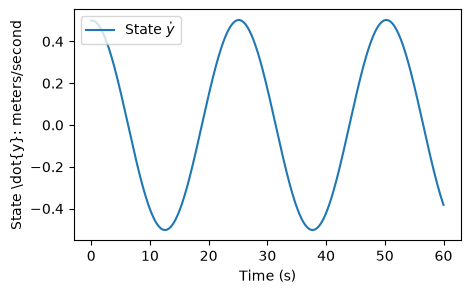

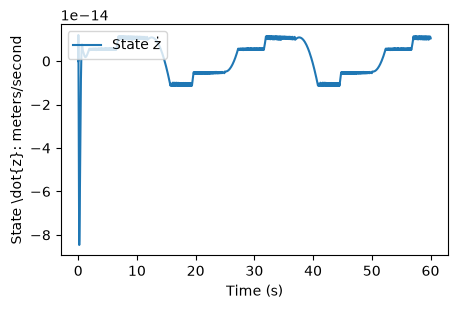

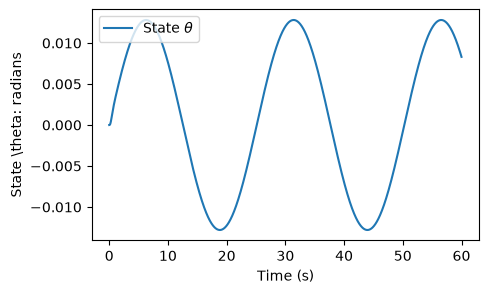

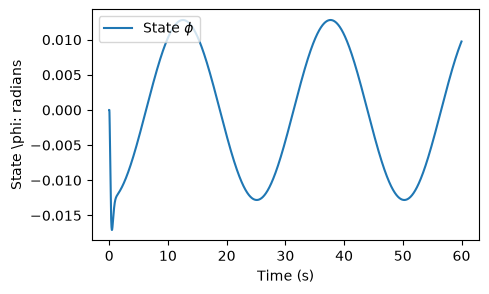

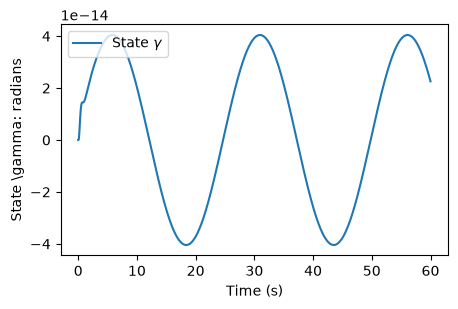

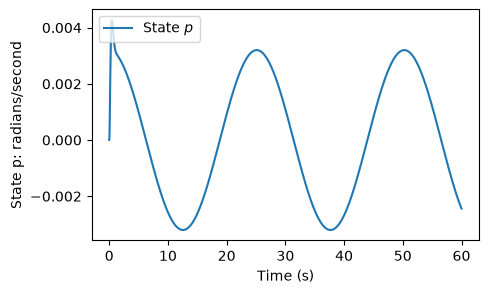

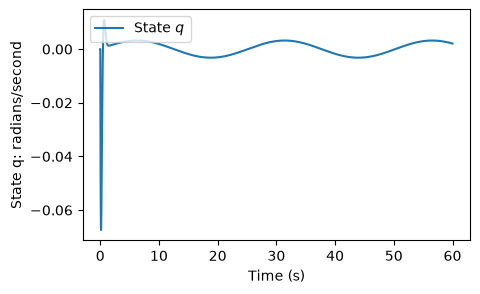

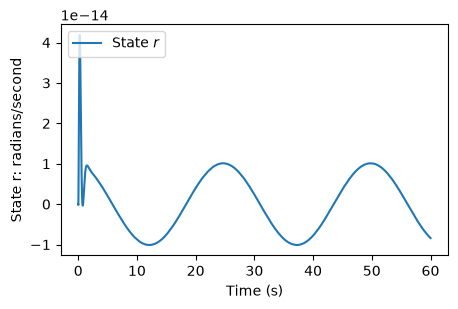

In [11]:
# Test 2: Circle

def get_circle(R, v_circ, t_0, t_f, dt):
    omega = v_circ/R
    time = list(np.linspace(t_0, t_f, int((t_f-t_0)/dt)))
    trajectory_vec = []
    for t in time:
        x = R*np.cos(omega*t)
        y = R*np.sin(omega*t)
        z = 1.0

        vx = -R*omega*np.sin(omega*t)
        vy =  R*omega*np.cos(omega*t)
        vz = 0.0

        trj_point = sp.Matrix([x, y, z, vx, vy, vz, 0, 0, 0, 0, 0, 0])
        trajectory_vec.append(trj_point)
    return trajectory_vec, time

# Testing:
states, times = get_circle(2, 0.5, 0, 60, 0.01)
time_hist, state_hist = follow_path(states, times)
states_np = np.array([np.array(s.tolist(), dtype=float).flatten() for s in state_hist])

for value in range(states_np.shape[1]):
    plt.figure(figsize=(5, 3))
    plt.plot(time_hist, states_np[:, value], label=f"State {f"${sp.latex(state_sym[value])}$"}")
    plt.legend(loc="upper left")
    plt.xlabel("Time (s)")
    plt.ylabel(f"State {sp.latex(state_sym[value])}: {units_vec[value]}")


plt.show()


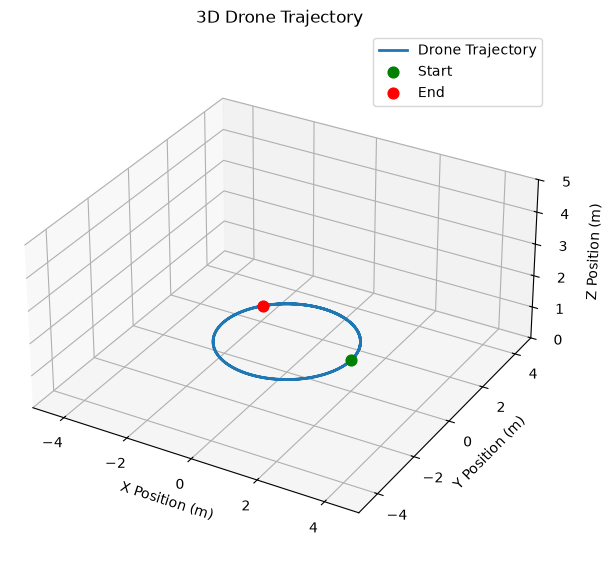

In [12]:
states_np = np.array([np.array(s.tolist(), dtype=float).flatten() for s in state_hist])

x = states_np[:, 0]
y = states_np[:, 1]
z = states_np[:, 2]

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')

ax.plot(x, y, z, label="Drone Trajectory", linewidth=2)

ax.scatter(x[0], y[0], z[0], color='green', s=60, label="Start")
ax.scatter(x[-1], y[-1], z[-1], color='red', s=60, label="End")

ax.set_xlabel("X Position (m)")
ax.set_ylabel("Y Position (m)")
ax.set_zlabel("Z Position (m)")
ax.set_xlim([-5,5])
ax.set_ylim([-5,5])
ax.set_zlim([0,5])
ax.set_title("3D Drone Trajectory")
ax.set_aspect('equal')
ax.legend()
plt.show()


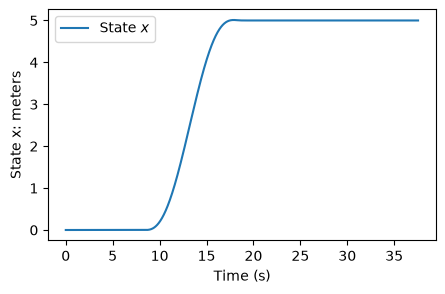

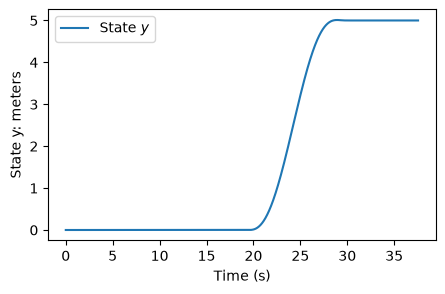

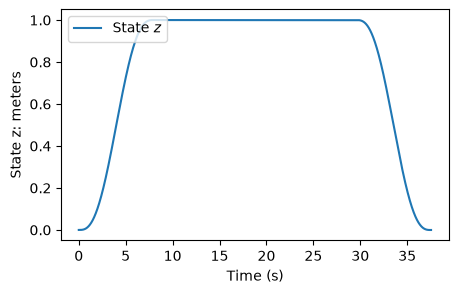

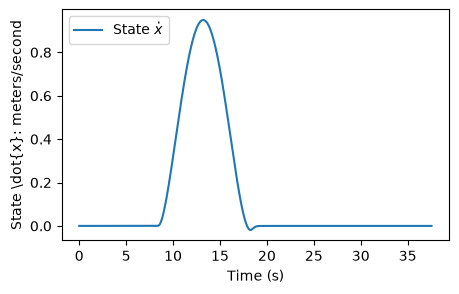

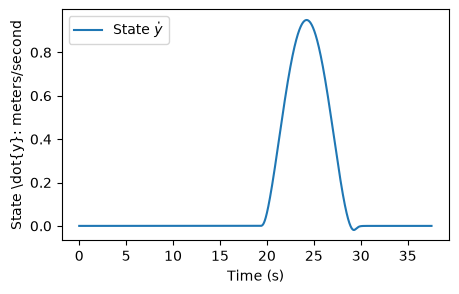

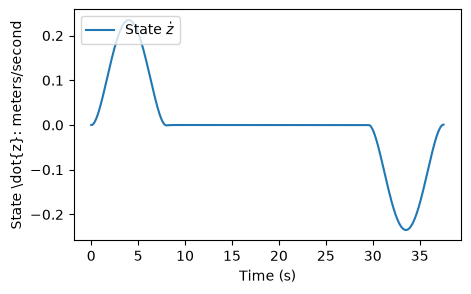

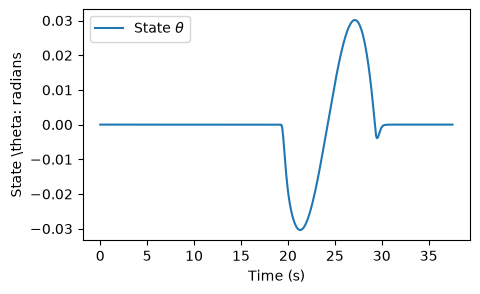

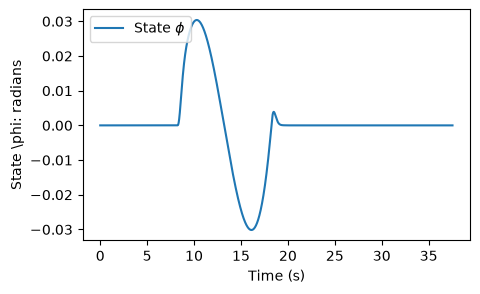

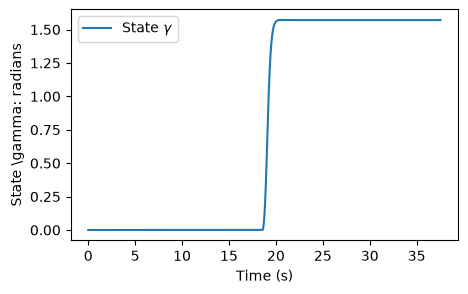

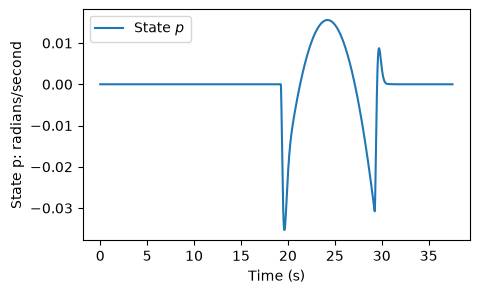

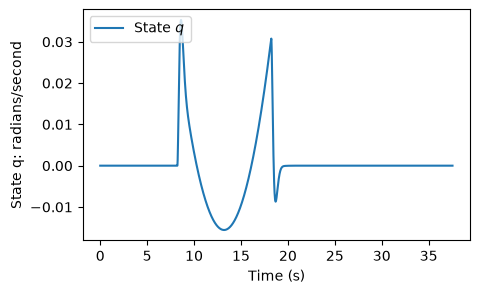

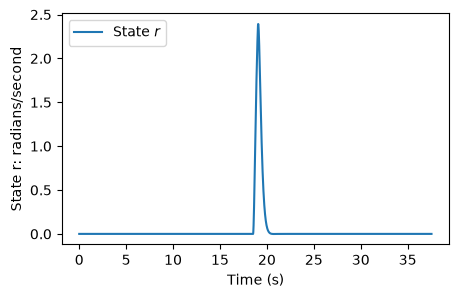

In [13]:


def get_trajectory_path():
    dt = 0.01
    step_1_time = 15
    steps = int(step_1_time / dt)

    trajectory_pts = []
    time_points = []
    current_time = 0.0
    def smooth(p_start, p_end, T):
        t_arr = np.arange(0, T + dt, dt)
        tau = t_arr / T
        s = p_start + (p_end - p_start) * (10 * tau**3 - 15 * tau**4 + 6 * tau**5)
        v = (p_end - p_start) * (30 * tau**2 - 60 * tau**3 + 30 * tau**4) / T
        a = (p_end - p_start) * (60 * tau - 180 * tau**2 + 120 * tau**3) / (T**2)
        return s, v, a

    z_pos, z_vel, _ = smooth(0.0, 1.0, 8.0)
    for zp, zv in zip(z_pos, z_vel):
        trajectory_pts.append(sp.Matrix([0, 0, zp, 0, 0, zv, 0, 0, 0, 0, 0, 0]))
        time_points.append(current_time)
        current_time += dt

    for i in range(20):
        trajectory_pts.append(sp.Matrix([0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0]))
        time_points.append(current_time)
        current_time += dt

    x_pos, x_vel, x_acc = smooth(0.0, 5, 10)
    for xp, xv, xa in zip(x_pos, x_vel, x_acc):
        trajectory_pts.append(sp.Matrix([xp, 0, 1, xv, 0, 0, 0, 0, 0, 0, 0, 0]))
        time_points.append(current_time)
        current_time += dt

    for i in range(30):
        trajectory_pts.append(sp.Matrix([5, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0]))
        time_points.append(current_time)
        current_time += dt

    yaw_points = np.linspace(0, np.pi/2, 51)
    for yaw in yaw_points:
        trajectory_pts.append(sp.Matrix([5, 0, 1, 0, 0, 0, 0, 0, yaw, 0, 0, 0]))
        time_points.append(current_time)
        current_time += dt

    for i in range(20):
        trajectory_pts.append(sp.Matrix([5, 0, 1, 0, 0, 0, 0, 0, np.pi/2, 0, 0, 0]))
        time_points.append(current_time)
        current_time += dt

    y_pos, y_vel, y_acc = smooth(0.0, 5.0, 10.0)
    for yp, yv, ya in zip(y_pos, y_vel, y_acc):
        trajectory_pts.append(sp.Matrix([5, yp, 1, 0, yv, 0, 0, 0, np.pi/2, 0, 0, 0]))
        time_points.append(current_time)
        current_time += dt

    for i in range(30):
        trajectory_pts.append(sp.Matrix([5, 5, 1, 0, 0, 0, 0, 0, np.pi/2, 0, 0, 0]))
        time_points.append(current_time)
        current_time += dt

    z_pos, z_vel, _ = smooth(1.0, 0.0, 8.0)
    for zp, zv in zip(z_pos, z_vel):
        trajectory_pts.append(sp.Matrix([5, 5, zp, 0, 0, zv, 0, 0, np.pi/2, 0, 0, 0]))
        time_points.append(current_time)
        current_time += dt


    return trajectory_pts, time_points

trajectory_pts, time_points = get_trajectory_path()


time_hist, state_hist = follow_path(trajectory_pts, time_points)
states_np = np.array([np.array(s.tolist() if hasattr(s, 'tolist') else s, dtype=float).flatten() for s in state_hist])

for value in range(states_np.shape[1]):
    plt.figure(figsize=(5, 3))
    plt.plot(time_hist, states_np[:, value], label=f"State {f"${sp.latex(state_sym[value])}$"}")
    plt.legend(loc="upper left")
    plt.xlabel("Time (s)")
    plt.ylabel(f"State {sp.latex(state_sym[value])}: {units_vec[value]}")

plt.show()


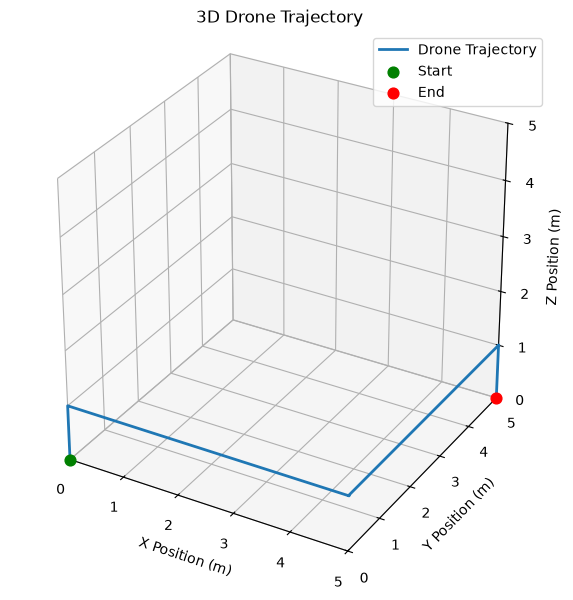

In [14]:
states_np = np.array([np.array(s.tolist(), dtype=float).flatten() for s in state_hist])

x = states_np[:, 0]
y = states_np[:, 1]
z = states_np[:, 2]

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')
ax.plot(x, y, z, label="Drone Trajectory", linewidth=2)

ax.scatter(x[0], y[0], z[0], color='green', s=60, label="Start")
ax.scatter(x[-1], y[-1], z[-1], color='red', s=60, label="End")

ax.set_xlabel("X Position (m)")
ax.set_ylabel("Y Position (m)")
ax.set_zlabel("Z Position (m)")
ax.set_xlim([0,5])
ax.set_ylim([0,5])
ax.set_zlim([0,5])
ax.set_title("3D Drone Trajectory")
ax.set_aspect('equal')
ax.legend()
plt.show()


In [16]:
# ============================================================
# FINAL REPORT FIGURES + VERIFICATION + ZIP EXPORT
# Does NOT modify dynamics or controller
# ============================================================

import os
import csv
import zipfile
from pathlib import Path

RESULTS_DIR = Path("AE352_results_figures")
RESULTS_DIR.mkdir(exist_ok=True)

DT = 0.01
RPM_LIMIT = 9250.0


# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------

def to_np(hist):
    return np.array([
        np.array(s.tolist(), dtype=float).flatten()
        for s in hist
    ])


def reconstruct_rpm(state_hist, target_hist):
    rpm_hist = []

    for x_state, target in zip(state_hist, target_hist):
        x_state = sp.Matrix(x_state)
        target = sp.Matrix(target)

        du = -K * (x_state - target)
        current_u = u_eq + du

        rpm_hist.append(
            np.array(current_u.tolist(), dtype=float).flatten()
        )

    return np.array(rpm_hist)


def savefig(name):
    plt.tight_layout()
    plt.savefig(
        RESULTS_DIR / f"{name}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.savefig(
        RESULTS_DIR / f"{name}.pdf",
        bbox_inches="tight"
    )
    plt.close()


def quintic_segment(p0, pf, T, dt=DT):
    t = np.arange(0, T + dt, dt)
    tau = t / T

    s = p0 + (pf-p0)*(10*tau**3 - 15*tau**4 + 6*tau**5)

    v = (pf-p0) * (
        30*tau**2 - 60*tau**3 + 30*tau**4
    ) / T

    return t, s, v


# ============================================================
# PHYSICAL MODEL
# ============================================================

weight = m * g
hover_thrust = weight / 4
hover_rpm = float(rpm_hover)

print("="*65)
print("PHYSICAL MODEL")
print("="*65)

print(f"Mass               : {m:.4f} kg")
print(f"Weight             : {weight:.3f} N")
print(f"Hover thrust/rotor : {hover_thrust:.3f} N")
print(f"Hover RPM          : {hover_rpm:.1f} RPM")
print(f"Ixx                : {Ixx:.5f} kg m^2")
print(f"Iyy                : {Iyy:.5f} kg m^2")
print(f"Izz                : {Izz:.5f} kg m^2")


# ============================================================
# TEST 1
# ASCEND TO 1 m, THEN HOVER FOR 120 s
# ============================================================

hover_targets = []
hover_times = []

current_t = 0.0

# 8 s smooth ascent
t_seg, z_seg, vz_seg = quintic_segment(0, 1, 8)

for z_cmd, vz_cmd in zip(z_seg, vz_seg):
    hover_targets.append(
        sp.Matrix([
            0,0,z_cmd,
            0,0,vz_cmd,
            0,0,0,
            0,0,0
        ])
    )

    hover_times.append(current_t)
    current_t += DT


# Hold at 1 m for full 120 seconds
for _ in range(int(120 / DT)):
    hover_targets.append(
        sp.Matrix([
            0,0,1,
            0,0,0,
            0,0,0,
            0,0,0
        ])
    )

    hover_times.append(current_t)
    current_t += DT


t_hover, x_hover = follow_path(
    hover_targets,
    hover_times
)

XH = to_np(x_hover)
UH = reconstruct_rpm(
    x_hover,
    hover_targets
)

# Index where 120 s hover period starts
hover_start_idx = len(z_seg)

XH_hold = XH[hover_start_idx:]
UH_hold = UH[hover_start_idx:]
TH_hold = np.array(t_hover[hover_start_idx:])

hover_mean_z = np.mean(XH_hold[:,2])
hover_max_z_error = np.max(
    np.abs(XH_hold[:,2] - 1)
)

hover_final_vz = XH[-1,5]


print("\n" + "="*65)
print("TEST 1 — HOVER")
print("="*65)

print(f"Total simulation time      : {t_hover[-1]:.2f} s")
print(f"Required hover duration    : 120.00 s")
print(f"Mean hover altitude        : {hover_mean_z:.6f} m")
print(f"Max hover altitude error   : {hover_max_z_error:.6f} m")
print(f"Final vertical speed       : {hover_final_vz:.6f} m/s")
print(f"Max RPM                    : {np.max(UH):.1f}")
print(f"Min RPM                    : {np.min(UH):.1f}")


# Hover altitude plot
plt.figure(figsize=(7,4))
plt.plot(t_hover, XH[:,2], label="Actual altitude")
plt.axhline(1.0, linestyle="--", label="Target altitude")
plt.xlabel("Time (s)")
plt.ylabel("Altitude z (m)")
plt.title("Test 1: Takeoff and 120 s Hover")
plt.legend()
plt.grid(True)
savefig("01_hover_altitude")


# Hover attitude
plt.figure(figsize=(7,4))
plt.plot(t_hover, np.degrees(XH[:,6]), label=r"$\theta$")
plt.plot(t_hover, np.degrees(XH[:,7]), label=r"$\phi$")
plt.plot(t_hover, np.degrees(XH[:,8]), label=r"$\gamma$")
plt.xlabel("Time (s)")
plt.ylabel("Euler angle (deg)")
plt.title("Test 1: Attitude During Hover")
plt.legend()
plt.grid(True)
savefig("02_hover_attitude")


# Hover rotor RPM
plt.figure(figsize=(7,4))
for i in range(4):
    plt.plot(t_hover, UH[:,i], label=f"Motor {i+1}")

plt.axhline(
    hover_rpm,
    linestyle="--",
    label="Hover RPM"
)

plt.xlabel("Time (s)")
plt.ylabel("Motor speed (RPM)")
plt.title("Test 1: Rotor Speeds")
plt.legend()
plt.grid(True)
savefig("03_hover_rpm")


# ============================================================
# TEST 2
# CIRCLE R = 2 m, v = 0.5 m/s, z = 1 m, 60 s
# ============================================================

circle_targets, circle_times = get_circle(
    2,
    0.5,
    0,
    60,
    DT
)

t_circle, x_circle = follow_path(
    circle_targets,
    circle_times
)

XC = to_np(x_circle)
UC = reconstruct_rpm(
    x_circle,
    circle_targets
)

radius = np.sqrt(
    XC[:,0]**2 + XC[:,1]**2
)

speed_xy = np.sqrt(
    XC[:,3]**2 + XC[:,4]**2
)

circle_mean_radius = np.mean(radius)
circle_max_radius_error = np.max(
    np.abs(radius - 2)
)

circle_mean_altitude = np.mean(XC[:,2])
circle_max_altitude_error = np.max(
    np.abs(XC[:,2] - 1)
)

circle_mean_speed = np.mean(speed_xy)


print("\n" + "="*65)
print("TEST 2 — CIRCULAR FLIGHT")
print("="*65)

print(f"Duration                  : {t_circle[-1]:.2f} s")
print(f"Mean radius               : {circle_mean_radius:.4f} m")
print(f"Max radius error          : {circle_max_radius_error:.4f} m")
print(f"Mean altitude             : {circle_mean_altitude:.4f} m")
print(f"Max altitude error        : {circle_max_altitude_error:.4f} m")
print(f"Mean horizontal speed     : {circle_mean_speed:.4f} m/s")
print(f"Max RPM                   : {np.max(UC):.1f}")
print(f"Min RPM                   : {np.min(UC):.1f}")


# Circle XY plot
plt.figure(figsize=(6,6))
plt.plot(XC[:,0], XC[:,1], label="Actual trajectory")

desired_circle = np.array([
    np.array(t.tolist(), dtype=float).flatten()
    for t in circle_targets
])

plt.plot(
    desired_circle[:,0],
    desired_circle[:,1],
    "--",
    label="Target trajectory"
)

plt.xlabel("X position (m)")
plt.ylabel("Y position (m)")
plt.title("Test 2: Circular Flight Path")
plt.axis("equal")
plt.grid(True)
plt.legend()
savefig("04_circle_xy")


# Circle performance
fig, ax1 = plt.subplots(figsize=(7,4))

ax1.plot(
    t_circle,
    radius,
    label="Radius"
)

ax1.axhline(
    2.0,
    linestyle="--",
    label="Target radius"
)

ax1.set_xlabel("Time (s)")
ax1.set_ylabel("Radius (m)")
ax1.grid(True)

ax2 = ax1.twinx()

ax2.plot(
    t_circle,
    speed_xy,
    label="Horizontal speed"
)

ax2.axhline(
    0.5,
    linestyle=":",
    label="Target speed"
)

ax2.set_ylabel("Speed (m/s)")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper right"
)

plt.title("Test 2: Radius and Flight Speed")
savefig("05_circle_performance")


# Circle RPM
plt.figure(figsize=(7,4))

for i in range(4):
    plt.plot(
        t_circle,
        UC[:,i],
        label=f"Motor {i+1}"
    )

plt.xlabel("Time (s)")
plt.ylabel("Motor speed (RPM)")
plt.title("Test 2: Rotor Speeds")
plt.legend()
plt.grid(True)
savefig("06_circle_rpm")


# ============================================================
# TEST 3
# FULL REQUIRED MISSION
# 5 m legs at average 1 m/s
# ============================================================

def get_report_mission():

    trajectory = []
    times = []

    t_now = 0.0

    def add_state(v):
        nonlocal t_now
        trajectory.append(sp.Matrix(v))
        times.append(t_now)
        t_now += DT


    # Takeoff: 0 -> 1 m in 8 s
    _, pos, vel = quintic_segment(
        0,
        1,
        8
    )

    for p_cmd, v_cmd in zip(pos, vel):
        add_state([
            0,0,p_cmd,
            0,0,v_cmd,
            0,0,0,
            0,0,0
        ])


    # Hover 2 s
    for _ in range(int(2/DT)):
        add_state([
            0,0,1,
            0,0,0,
            0,0,0,
            0,0,0
        ])


    # X: 5 m in 5 s => average 1 m/s
    _, pos, vel = quintic_segment(
        0,
        5,
        5
    )

    for p_cmd, v_cmd in zip(pos, vel):
        add_state([
            p_cmd,0,1,
            v_cmd,0,0,
            0,0,0,
            0,0,0
        ])


    # Stop / hover 2 s
    for _ in range(int(2/DT)):
        add_state([
            5,0,1,
            0,0,0,
            0,0,0,
            0,0,0
        ])


    # Yaw 90 deg over 5 s
    yaw_t = np.arange(
        0,
        5 + DT,
        DT
    )

    tau = yaw_t / 5

    yaw = (
        np.pi/2
    ) * (
        10*tau**3
        - 15*tau**4
        + 6*tau**5
    )

    for yaw_cmd in yaw:
        add_state([
            5,0,1,
            0,0,0,
            0,0,yaw_cmd,
            0,0,0
        ])


    # Hover after yaw 2 s
    for _ in range(int(2/DT)):
        add_state([
            5,0,1,
            0,0,0,
            0,0,np.pi/2,
            0,0,0
        ])


    # Y: 5 m in 5 s => average 1 m/s
    _, pos, vel = quintic_segment(
        0,
        5,
        5
    )

    for p_cmd, v_cmd in zip(pos, vel):
        add_state([
            5,p_cmd,1,
            0,v_cmd,0,
            0,0,np.pi/2,
            0,0,0
        ])


    # Stop / hover 2 s
    for _ in range(int(2/DT)):
        add_state([
            5,5,1,
            0,0,0,
            0,0,np.pi/2,
            0,0,0
        ])


    # Landing: 1 -> 0 m over 8 s
    _, pos, vel = quintic_segment(
        1,
        0,
        8
    )

    for p_cmd, v_cmd in zip(pos, vel):
        add_state([
            5,5,p_cmd,
            0,0,v_cmd,
            0,0,np.pi/2,
            0,0,0
        ])

    return trajectory, times


mission_targets, mission_times = get_report_mission()

t_mission, x_mission = follow_path(
    mission_targets,
    mission_times
)

XM = to_np(x_mission)

UM = reconstruct_rpm(
    x_mission,
    mission_targets
)

landing_speed = abs(XM[-1,5])

mission_max_rpm = np.max(UM)
mission_min_rpm = np.min(UM)


print("\n" + "="*65)
print("TEST 3 — FULL MISSION")
print("="*65)

print(f"Duration                  : {t_mission[-1]:.2f} s")
print(f"Final x                   : {XM[-1,0]:.4f} m")
print(f"Final y                   : {XM[-1,1]:.4f} m")
print(f"Final z                   : {XM[-1,2]:.6f} m")
print(f"Final yaw                 : {np.degrees(XM[-1,8]):.3f} deg")
print(f"Landing vertical speed    : {landing_speed:.6f} m/s")
print(f"Maximum altitude          : {np.max(XM[:,2]):.4f} m")
print(f"Maximum RPM               : {mission_max_rpm:.1f}")
print(f"Minimum RPM               : {mission_min_rpm:.1f}")

print(
    "Landing requirement      :",
    "PASS"
    if landing_speed <= 0.01
    else "FAIL"
)

print(
    "RPM limit                :",
    "PASS"
    if (
        mission_max_rpm <= RPM_LIMIT
        and mission_min_rpm >= 0
    )
    else "FAIL"
)


# 3D mission trajectory
fig = plt.figure(figsize=(7,6))

ax = fig.add_subplot(
    111,
    projection="3d"
)

ax.plot(
    XM[:,0],
    XM[:,1],
    XM[:,2],
    linewidth=2
)

ax.scatter(
    XM[0,0],
    XM[0,1],
    XM[0,2],
    label="Start"
)

ax.scatter(
    XM[-1,0],
    XM[-1,1],
    XM[-1,2],
    label="End"
)

ax.set_xlabel("X position (m)")
ax.set_ylabel("Y position (m)")
ax.set_zlabel("Z position (m)")
ax.set_title("Test 3: Complete Mission Trajectory")
ax.legend()

plt.savefig(
    RESULTS_DIR / "07_mission_3d.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    RESULTS_DIR / "07_mission_3d.pdf",
    bbox_inches="tight"
)

plt.close()


# Position vs time
plt.figure(figsize=(7,4))

plt.plot(
    t_mission,
    XM[:,0],
    label="x"
)

plt.plot(
    t_mission,
    XM[:,1],
    label="y"
)

plt.plot(
    t_mission,
    XM[:,2],
    label="z"
)

plt.xlabel("Time (s)")
plt.ylabel("Position (m)")
plt.title("Test 3: Position History")
plt.legend()
plt.grid(True)
savefig("08_mission_position")


# Attitude
plt.figure(figsize=(7,4))

plt.plot(
    t_mission,
    np.degrees(XM[:,6]),
    label=r"$\theta$"
)

plt.plot(
    t_mission,
    np.degrees(XM[:,7]),
    label=r"$\phi$"
)

plt.plot(
    t_mission,
    np.degrees(XM[:,8]),
    label=r"$\gamma$"
)

plt.xlabel("Time (s)")
plt.ylabel("Euler angle (deg)")
plt.title("Test 3: Attitude History")
plt.legend()
plt.grid(True)
savefig("09_mission_attitude")


# Rotor RPM
plt.figure(figsize=(7,4))

for i in range(4):
    plt.plot(
        t_mission,
        UM[:,i],
        label=f"Motor {i+1}"
    )

plt.axhline(
    RPM_LIMIT,
    linestyle="--",
    label="RPM limit"
)

plt.xlabel("Time (s)")
plt.ylabel("Motor speed (RPM)")
plt.title("Test 3: Rotor Commands")
plt.legend()
plt.grid(True)
savefig("10_mission_rpm")


# Landing detail
landing_window = max(
    0,
    len(XM) - int(10/DT)
)

plt.figure(figsize=(7,4))

plt.plot(
    np.array(t_mission[landing_window:]),
    XM[landing_window:,2],
    label="Altitude"
)

plt.xlabel("Time (s)")
plt.ylabel("Altitude (m)")
plt.title(
    f"Test 3: Landing — final |vz| = "
    f"{landing_speed:.4f} m/s"
)

plt.grid(True)
plt.legend()
savefig("11_landing")


# ============================================================
# SUMMARY TABLE
# ============================================================

metrics = [
    ["Mass (kg)", m],
    ["Weight (N)", weight],
    ["Hover RPM", hover_rpm],

    ["Hover mean altitude (m)", hover_mean_z],
    ["Hover max altitude error (m)", hover_max_z_error],

    ["Circle mean radius (m)", circle_mean_radius],
    ["Circle max radius error (m)", circle_max_radius_error],
    ["Circle mean speed (m/s)", circle_mean_speed],
    ["Circle mean altitude (m)", circle_mean_altitude],

    ["Mission landing speed (m/s)", landing_speed],
    ["Mission final yaw (deg)", np.degrees(XM[-1,8])],

    ["Mission max RPM", mission_max_rpm],
    ["Mission min RPM", mission_min_rpm],
]


with open(
    RESULTS_DIR / "results_metrics.csv",
    "w",
    newline=""
) as f:

    writer = csv.writer(f)
    writer.writerow(
        ["Metric", "Value"]
    )

    writer.writerows(metrics)


# Summary TXT
with open(
    RESULTS_DIR / "results_summary.txt",
    "w"
) as f:

    f.write("AE352 DRONE PROJECT RESULTS\n\n")

    for name, val in metrics:
        f.write(
            f"{name}: {val}\n"
        )


# ============================================================
# ZIP EVERYTHING
# ============================================================

zip_name = "AE352_results_figures.zip"

with zipfile.ZipFile(
    zip_name,
    "w",
    zipfile.ZIP_DEFLATED
) as zf:

    for path in RESULTS_DIR.iterdir():
        zf.write(
            path,
            arcname=path.name
        )


print("\n" + "="*65)
print("EXPORT COMPLETE")
print("="*65)

print(
    f"Figures saved in: "
    f"{RESULTS_DIR.resolve()}"
)

print(
    f"ZIP saved as: "
    f"{Path(zip_name).resolve()}"
)

print("\nUpload the ZIP contents to Overleaf.")

PHYSICAL MODEL
Mass               : 1.4367 kg
Weight             : 14.094 N
Hover thrust/rotor : 3.524 N
Hover RPM          : 5144.5 RPM
Ixx                : 0.01820 kg m^2
Iyy                : 0.01690 kg m^2
Izz                : 0.02530 kg m^2

TEST 1 — HOVER
Total simulation time      : 128.00 s
Required hover duration    : 120.00 s
Mean hover altitude        : 1.000000 m
Max hover altitude error   : 0.000197 m
Final vertical speed       : -0.000000 m/s
Max RPM                    : 5168.2
Min RPM                    : 5120.7

TEST 2 — CIRCULAR FLIGHT
Duration                  : 60.00 s
Mean radius               : 2.0098 m
Max radius error          : 0.0099 m
Mean altitude             : 1.0000 m
Max altitude error        : 0.0000 m
Mean horizontal speed     : 0.5024 m/s
Max RPM                   : 5168.0
Min RPM                   : 5120.9

TEST 3 — FULL MISSION
Duration                  : 39.04 s
Final x                   : 5.0000 m
Final y                   : 5.0000 m
Final z         